# Do messages passed around a loop of language models forget where they started?

| | |
| --- | --- |
| **Question** | When four language-model subjects pass a message around a loop, each hearing only the previous message, do runs that start from different sentences come to say, and represent, the same thing? Does it depend on how each subject chooses its words? |
| **Requires** | GPT-2 and DistilGPT-2 weights from Hugging Face (about 850 MB). CPU or GPU, a few minutes. |
| **Lessons used** | [1. Your first subject](../lessons/01_your_first_subject.ipynb), [9. Closed loop](../lessons/09_closed_loop.ipynb) |

## Background

In the children's game of telephone, a message passed from person to person drifts until it no longer resembles the original. Studies of communication between agents connect several systems so that the output of one becomes the input of the next, and ask what survives the chain.

Language models that always choose the most probable next word (greedy decoding) are known to fall into repetitive text. In a loop, that could make every run end in the same few phrases whatever it started from. Sampling words in proportion to their probability adds variety, which could keep runs apart. Which happens, and how fast, is an empirical question.

Besides the text, the subjects' internal activity can be recorded while the loop runs: each listener's representation of the message it has just heard.

## Hypothesis

With greedy decoding, messages from different starting sentences become more similar, in their words and in the listeners' representations, than the first responses were. With sampling, they do not.

## Method

**Subjects.** GPT-2 (124M parameters) and DistilGPT-2 (82M), alternating around a loop of four: GPT-2, DistilGPT-2, GPT-2, DistilGPT-2. Each subject's `policy` receives the previous message and continues it with 20 new tokens; the continuation alone is the next message. Each subject hears only the last message, not the conversation.

**Runs.** 12 starting sentences on unrelated topics; 5 rounds of 4 messages, so 20 messages per run. Two decoding rules: greedy, and sampling (temperature 1, the 50 most probable tokens, fixed seed per run). Subjects are reset before and after every run.

**Recording.** An `ActivationWindow` on each subject's last transformer block keeps the forward pass that reads the incoming message (the first pass of each `generate` call); its average over the message's tokens is that listener's representation of the message.

**Measures.** (1) Word overlap: the mean Jaccard similarity of word sets between every pair of runs, at each of the 20 positions. (2) Representation similarity: the mean cosine similarity between runs of the representations held by the same subject at the same position, each centred by that model's mean representation over every message it heard in both conditions. (3) The number of distinct final messages among the 12 runs.

## Setup

Imports and the two networks' weights and tokenizers, downloaded from Hugging Face on first use.

In [1]:
# Keep the output short: no progress bars, no library warnings.
import warnings
from functools import partialmethod
from tqdm.auto import tqdm
import tqdm as _tqdm
for _bar in (tqdm, _tqdm.tqdm):
    _bar.__init__ = partialmethod(_bar.__init__, disable=True)
warnings.filterwarnings('ignore')
import os
os.environ['BS_INSTALL_DEPENDENCIES'] = 'no'      # every requirement is already installed

import itertools
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

device = 'cuda' if torch.cuda.is_available() else 'cpu'      # a GPU if there is one
networks, tokenizers = {}, {}
for name in ('gpt2', 'distilgpt2'):
    tokenizers[name] = AutoTokenizer.from_pretrained(name)
    networks[name] = AutoModelForCausalLM.from_pretrained(name).to(device).eval()

## The subjects

Each subject is a `BrainScoreModel` whose `policy` turns an observation into an action: here, the incoming message into a continuation. `PolicyWrapper(max_history=0)` gives it no memory of earlier turns, so each subject hears only the last message.

The policy also records: an `ActivationWindow` on the network's last transformer block captures the pass that reads the incoming message, and its average over tokens is stored as that listener's representation.

In [2]:
from brainscore_core import BrainScoreModel
from brainscore.activation_window import ActivationWindow
from brainscore.model_helpers.policy_wrapper import PolicyWrapper

LAST_BLOCK = {'gpt2': 'transformer.h.11', 'distilgpt2': 'transformer.h.5'}
representations = {}        # (decoding, run, position) -> the listener's representation of the message it heard

def make_policy(name, decoding, state):
    network, tokenizer = networks[name], tokenizers[name]
    def policy(observation, history):
        message = observation['incoming']
        ids = tokenizer(message, return_tensors='pt').input_ids[:, -48:].to(device)    # at most the last 48 tokens
        options = dict(do_sample=False) if decoding == 'greedy' else dict(do_sample=True, temperature=1.0, top_k=50)
        if decoding == 'sampling':
            torch.manual_seed(1000 * state['run'] + state['position'])                  # a fixed seed per message
        with ActivationWindow(network, layers=[LAST_BLOCK[name]]) as window, torch.no_grad():
            output = network.generate(ids, max_new_tokens=20, pad_token_id=tokenizer.eos_token_id, **options)
        heard = window.captures[0].tensor[0].float().mean(dim=0).numpy()   # first pass reads the message
        representations[decoding, state['run'], state['position']] = (name, heard)
        state['position'] += 1
        # The next message is the continuation alone, without the message it continues.
        return tokenizer.decode(output[0, ids.shape[1]:], skip_special_tokens=True).strip() or '...'
    return policy

ORDER = ['gpt2', 'distilgpt2', 'gpt2', 'distilgpt2']

def subjects_for(decoding, state):
    """The four subjects of one run, in loop order."""
    return [BrainScoreModel(identifier=f'{name}-{i}',
                            policy=PolicyWrapper(policy=make_policy(name, decoding, state), max_history=0))
            for i, name in enumerate(ORDER)]

## The experiment

### Stimuli

Twelve starting sentences on unrelated topics.

In [3]:
STARTS = [
    'The old lighthouse keeper climbed the stairs every night',
    'Interest rates rose again this quarter as inflation persisted',
    'My grandmother grew tomatoes in a small garden behind the house',
    'The striker scored twice in the second half to win the match',
    'Mitochondria produce most of the energy a cell uses',
    'We missed the last train and had to walk home in the rain',
    'The committee voted to delay the bridge project for another year',
    'A violin needs new strings every few months if you play daily',
    'The comet will be visible from the southern hemisphere in March',
    'She opened the letter and recognized her brother handwriting',
    'Our team shipped the new version of the app on Friday',
    'Volcanic soil is unusually rich in nutrients for crops',
]

### Task

A mediator decides what each subject hears. The first subject hears the starting sentence; every later one hears the previous message. Five rounds of the four subjects make 20 messages per run.

In [4]:
from brainscore.harnesses.multi_agent import multi_agent_rollout, DialogueMediator

class StartFrom(DialogueMediator):
    """The first subject hears the starting sentence; every later one hears the previous message."""
    def __init__(self, start):
        super().__init__(task='continue the message')
        self.start = start
    def observe(self, agent_id, incoming):
        return super().observe(agent_id, self.start if incoming is None else incoming)

### Conditions

Two decoding rules, each run on all 12 starting sentences: `greedy` (always the most probable token) and `sampling` (temperature 1, the 50 most probable tokens).

## Run

Each run builds fresh subjects, resets them, plays the loop and resets them again. The transcript holds every subject's action in order.

In [5]:
messages = {}                   # decoding -> one list of 20 messages per run
for decoding in ('greedy', 'sampling'):
    runs = []
    for run, start in enumerate(STARTS):
        state = {'run': run, 'position': 0}       # read by the policies: which run, which message
        subjects = subjects_for(decoding, state)
        for s in subjects:
            s.reset()
        try:
            transcript = multi_agent_rollout(subjects, StartFrom(start), n_turns=5)
        finally:
            for s in subjects:
                s.reset()
        runs.append([entry['action'] for entry in transcript])
    messages[decoding] = runs

## Read results back

The transcripts give 20 messages per run; the representations, one vector per run and position, recorded by the listener at that position.

In [6]:
for decoding in ('greedy', 'sampling'):
    print(f'{decoding}: {len(messages[decoding])} runs x {len(messages[decoding][0])} messages')
print('representations:', len(representations), 'vectors, e.g.',
      {name: vector.shape for name, vector in [representations['greedy', 0, 0], representations['greedy', 0, 1]]})

for decoding in ('greedy', 'sampling'):
    print(f'\n{decoding}, run 0, from: {STARTS[0]!r}')
    for position in (0, 1, 2, 19):
        print(f'  message {position + 1:2d}: {messages[decoding][0][position]!r}')

greedy: 12 runs x 20 messages
sampling: 12 runs x 20 messages
representations: 480 vectors, e.g. {'gpt2': (768,), 'distilgpt2': (768,)}

greedy, run 0, from: 'The old lighthouse keeper climbed the stairs every night'
  message  1: ', and the old lighthouse keeper was always there.\n\n"I was always there, and I'
  message  2: 'was always there, and I was always there, and I was always there, and I was always'
  message  3: 'there, and I was always there, and I was always there, and I was always there,'
  message 20: 'was always there, and I was always there, and I was always there, and I was always'

sampling, run 0, from: 'The old lighthouse keeper climbed the stairs every night'
  message  1: ". He'd used a few different sets of mirrors, but there was no way of looking behind them"
  message  2: '. There was no obvious way he felt he could see their surroundings, but his eyes would sometimes turn'
  message  3: 'sharp.\n\n"Do you think that\'s because you\'re in the dark?"\n\n"'
  mes

## Analysis

In [7]:
def words(text):
    return set(text.lower().split())

def word_overlap(runs, position):
    """Mean Jaccard similarity of word sets between every pair of runs, at one position."""
    pairs = itertools.combinations(range(len(runs)), 2)
    return np.mean([len(words(runs[a][position]) & words(runs[b][position])) /
                    max(1, len(words(runs[a][position]) | words(runs[b][position]))) for a, b in pairs])

def representation_similarity(decoding, position):
    """Mean cosine similarity between runs of the centred representations at one position."""
    vectors = np.stack([representations[decoding, run, position][1] for run in range(len(STARTS))])
    name = representations[decoding, 0, position][0]
    # One reference per model, pooled over both decoding rules, so the same input gets the same value.
    mean = np.mean([v for (n, v) in representations.values() if n == name], axis=0)
    v = vectors - mean
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    similarity = v @ v.T
    return similarity[np.triu_indices(len(v), 1)].mean()      # each pair of runs once

## Results

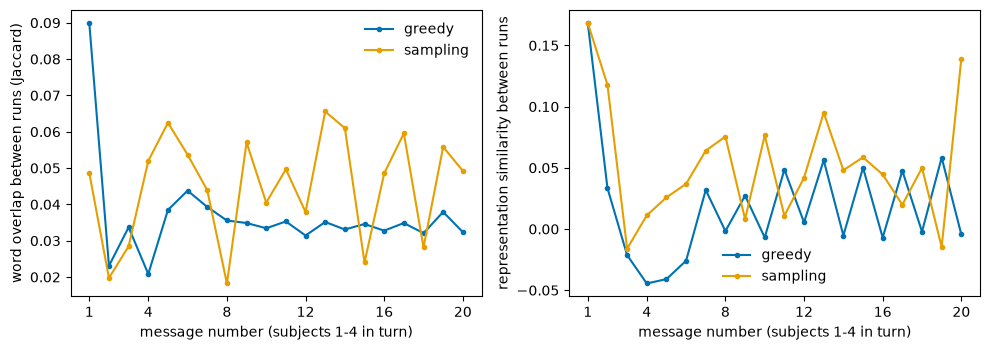

In [8]:
positions = np.arange(20)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for decoding, color in (('greedy', '#0072B2'), ('sampling', '#E69F00')):
    axes[0].plot(positions + 1, [word_overlap(messages[decoding], p) for p in positions], '-o', ms=3, color=color, label=decoding)
    axes[1].plot(positions + 1, [representation_similarity(decoding, p) for p in positions], '-o', ms=3, color=color, label=decoding)
axes[0].set_ylabel('word overlap between runs (Jaccard)')
axes[1].set_ylabel('representation similarity between runs')
for ax in axes:
    ax.set_xlabel('message number (subjects 1-4 in turn)'); ax.set_xticks([1, 4, 8, 12, 16, 20]); ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [9]:
starts = [[s] for s in STARTS]                # the starting sentences, as one-message runs
print(f'starting sentences: word overlap {word_overlap(starts, 0):.3f}')
for decoding in ('greedy', 'sampling'):
    first, last = word_overlap(messages[decoding], 0), word_overlap(messages[decoding], 19)
    # Position 0's listener heard the starting sentences; position 19's heard message 19.
    r_start, r_last = representation_similarity(decoding, 0), representation_similarity(decoding, 19)
    distinct = len({run[-1] for run in messages[decoding]})
    print(f'{decoding:8s} word overlap: message 1 {first:.3f}, message 20 {last:.3f} | '
          f'representation similarity: starting sentences {r_start:+.3f}, message 19 {r_last:+.3f} | '
          f'{distinct} distinct final messages of {len(STARTS)}')

starting sentences: word overlap 0.046
greedy   word overlap: message 1 0.090, message 20 0.032 | representation similarity: starting sentences +0.168, message 19 -0.004 | 12 distinct final messages of 12
sampling word overlap: message 1 0.049, message 20 0.049 | representation similarity: starting sentences +0.168, message 19 +0.139 | 12 distinct final messages of 12


## Conclusion and limits

The hypothesis was not supported: neither loop forgot its starting point by converging on a shared message. With greedy decoding, each run fell within a few messages into its own repetitive phrase (run 0 repeats "I was always there" from message 2 on), so runs became less alike, not more: word overlap between runs fell from 0.090 for the first responses to 0.032 by message 20, below the 0.046 of the unrelated starting sentences, and all 12 final messages differed. With sampling, word overlap stayed near the starting level (0.049) and the text drifted to new topics. The listeners' representations agree: similarity between runs fell from 0.17 for the starting sentences to about zero within four messages under both rules; under greedy decoding it then alternates with the listener, GPT-2 and DistilGPT-2 responding differently to the same repetitive text. The loops lose their starting point by drifting apart, each to its own attractor, rather than by converging.

Limits: two small models from one family; 12 starting sentences; 20-token messages; one seed per sampled run. The representation measure compares runs at the same position, which always holds the same listener, so it is not affected by differences between the two models' spaces; it does not say whether the two models represent a message alike.

[Lessons](../lessons/) · [Documentation](../../docs/README.md)